=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        Good       0.25      0.27      0.26        22
    Moderate       0.54      0.57      0.55        95
        Poor       0.59      0.57      0.58       119
      Severe       0.59      0.55      0.57        49

    accuracy                           0.54       285
   macro avg       0.49      0.49      0.49       285
weighted avg       0.55      0.54      0.55       285


Saved plot as 'classification_confusion_matrix.png'


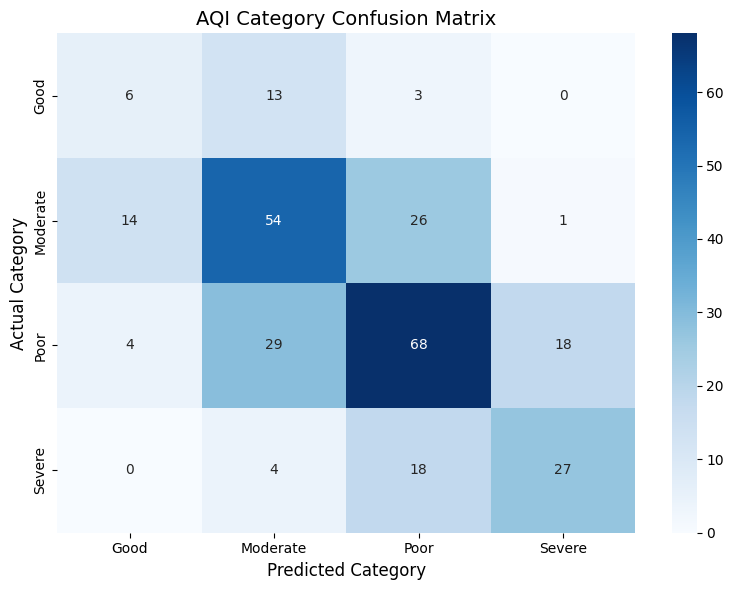

=== DATASET IMBALANCE & RECALL CHECK ===
Total 'Severe' test samples: 49.0
'Severe' Category Recall Score: 55.10%


In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix


# 1. LOADING DATA & PREPARING CATEGORIES

# Load the feature (X) and target (y) files provided by Person 1
X = pd.read_csv('/content/X_features.csv')
y_raw = pd.read_csv('/content/y_target.csv')

# Grabbing the numeric target column
y_numeric = y_raw.iloc[:, 0]

# Helper function to convert numeric AQI into 4-bucket text categories
def convert_aqi_to_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Moderate"
    elif aqi <= 200:
        return "Poor"
    else:
        return "Severe"

# Applying conversion to get text categories
y_categorical = y_numeric.apply(convert_aqi_to_category)


# 2. TRAIN MODEL TO GENERATE y_test AND y_pred

# Splitting the dataset into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical
)

# Train a Decision Tree classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Generating predictions for the test set
y_pred = clf.predict(X_test)



# 3. TASK 2: METRIC CALCULATION

categories = ["Good", "Moderate", "Poor", "Severe"]

print("=== CLASSIFICATION REPORT ===")
# Generates Accuracy, Precision, Recall, and F1-score for each category
report = classification_report(y_test, y_pred, labels=categories, zero_division=0)
print(report)


# 4. TASK 2: CONFUSION MATRIX HEATMAP

cm = confusion_matrix(y_test, y_pred, labels=categories)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=categories,
    yticklabels=categories
)

plt.title('AQI Category Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Category', fontsize=12)
plt.ylabel('Actual Category', fontsize=12)
plt.tight_layout()

# Saving image for GitHub repository
plt.savefig('classification_confusion_matrix.png', dpi=300)
print("\nSaved plot as 'classification_confusion_matrix.png'")
plt.show()



# 5. TASK 2: IMBALANCE CHECK (Severe Recall)

report_dict = classification_report(y_test, y_pred, labels=categories, output_dict=True, zero_division=0)

severe_recall = report_dict.get("Severe", {}).get("recall", 0.0)
severe_support = report_dict.get("Severe", {}).get("support", 0)

print("=== DATASET IMBALANCE & RECALL CHECK ===")
print(f"Total 'Severe' test samples: {severe_support}")
print(f"'Severe' Category Recall Score: {severe_recall:.2%}")

if severe_recall < 0.70:
    print("WARNING: Low Recall for 'Severe' days! The model may be missing rare, high-risk pollution days to inflate overall accuracy.")
else:
    print("SUCCESS: The model reliably identifies 'Severe' days despite class imbalances.")